# Models

Here I tune my two real models, logistic regression and a decision tree, and compare them with the baselines from notebook 03. Like before, I only use the training set with the same 5 folds. The test set stays untouched.

In [1]:
# Add the project folder to the path so `from src import ...` works when this
# notebook is run from the notebooks folder.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_predict

from src.baselines import SCORING, SecondAttemptRule
from src.clean import clean
from src.evaluation import make_cv, split_by_lifter
from src.features import FEATURES, build_features
from src.models import LR_GRID, TREE_GRID, make_decision_tree, make_logistic_regression, tune
from src.paths import INTERIM, REPORTS

cohort = pd.read_csv(INTERIM / 'audit_cohort.csv.gz', dtype=str, keep_default_na=False)
cleaned, _ = clean(cohort)
table = build_features(cleaned)

# I only keep the training side. The test set isn't used anywhere in this notebook.
train, _ = split_by_lifter(table)
X_train, y_train, groups_train = train[FEATURES], train['made'], train['Name']
print('training rows:', len(X_train))

training rows: 369880


## 1. Logistic regression

In [2]:
start = time.perf_counter()
lr_search = tune(make_logistic_regression(), LR_GRID, X_train, y_train, groups_train)
print(f'took {time.perf_counter() - start:.0f} seconds')
print('best settings:', lr_search.best_params_)

# Mean and std of balanced accuracy across the 5 folds for each C I tried.
lr_table = pd.DataFrame({
    'C': lr_search.cv_results_['param_model__C'],
    'balanced_accuracy_mean': lr_search.cv_results_['mean_test_balanced_accuracy'],
    'balanced_accuracy_std': lr_search.cv_results_['std_test_balanced_accuracy'],
}).round(4)
lr_table

took 32 seconds
best settings: {'model__C': 10}


,C,balanced_accuracy_mean,balanced_accuracy_std
0,0.01,0.6113,0.0015
1,0.10,0.6113,0.0015
2,1.00,0.6113,0.0015
3,10.00,0.6113,0.0015


## 2. Decision tree

In [3]:
start = time.perf_counter()
tree_search = tune(make_decision_tree(), TREE_GRID, X_train, y_train, groups_train)
print(f'took {time.perf_counter() - start:.0f} seconds')
print('best settings:', tree_search.best_params_)

# Mean balanced accuracy across the 5 folds. Rows are max_depth, columns are
# min_samples_leaf.
tree_table = pd.DataFrame({
    'max_depth': tree_search.cv_results_['param_model__max_depth'],
    'min_samples_leaf': tree_search.cv_results_['param_model__min_samples_leaf'],
    'balanced_accuracy_mean': tree_search.cv_results_['mean_test_balanced_accuracy'],
}).pivot(index='max_depth', columns='min_samples_leaf', values='balanced_accuracy_mean')
tree_table.round(4)

took 49 seconds
best settings: {'model__max_depth': 8, 'model__min_samples_leaf': 50}


min_samples_leaf,1,50,200
max_depth,,,
3,0.6030,0.6030,0.6030
5,0.6119,0.6120,0.6120
8,0.6170,0.6174,0.6173
12,0.6122,0.6131,0.6160


## 3. Models next to the baselines

In [4]:
def best_row(search):
    """The fold scores for the setting each search picked, with the same column names
    as baseline_results.csv."""
    i = search.best_index_
    row = {}
    for metric in SCORING:
        row[f'{metric}_mean'] = search.cv_results_[f'mean_test_{metric}'][i]
        row[f'{metric}_std'] = search.cv_results_[f'std_test_{metric}'][i]
    return row

baseline_results = pd.read_csv(REPORTS / 'baseline_results.csv', index_col=0)
models = pd.DataFrame({'logistic regression': best_row(lr_search),
                       'decision tree': best_row(tree_search)}).T
model_results = pd.concat([baseline_results, models])[baseline_results.columns].round(4)
model_results.index.name = 'model'
model_results.to_csv(REPORTS / 'model_results.csv')

# The scores I care about most go first.
first = [f'{m}_{s}' for m in ['balanced_accuracy', 'roc_auc', 'accuracy', 'recall_missed']
         for s in ['mean', 'std']]
model_results[first + [c for c in model_results.columns if c not in first]]

,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,accuracy_mean,accuracy_std,recall_missed_mean,recall_missed_std,precision_made_mean,precision_made_std,recall_made_mean,recall_made_std,f1_made_mean,f1_made_std,precision_missed_mean,precision_missed_std,f1_missed_mean,f1_missed_std
model,,,,,,,,,,,,,,,,,,
always made,0.5000,0.0000,0.5000,0.0000,0.6102,0.0000,0.0000,0.0000,0.6102,0.0000,1.0000,0.0000,0.7579,0.0000,0.0000,0.0000,0.0000,0.0000
second-attempt rule,0.5553,0.0010,0.5553,0.0010,0.6383,0.0008,0.1792,0.0022,0.6399,0.0006,0.9315,0.0008,0.7586,0.0004,0.6256,0.0030,0.2785,0.0029
logistic regression,0.6113,0.0015,0.6562,0.0019,0.6209,0.0016,0.5680,0.0029,0.7035,0.0013,0.6546,0.0026,0.6782,0.0016,0.5123,0.0018,0.5387,0.0019
decision tree,0.6174,0.0016,0.6629,0.0022,0.6213,0.0036,0.6000,0.0122,0.7131,0.0024,0.6349,0.0132,0.6716,0.0066,0.5122,0.0042,0.5525,0.0033


## Model settings and tuning

I tuned both models with a grid search on the same 5 folds as my baselines, so each lifter stays inside one fold, and I picked the setting with the best mean balanced accuracy. For logistic regression I tried C = 0.01, 0.1, 1 and 10. All four came out at 0.6113 balanced accuracy to 4 decimal places, so C made no real difference here. The search kept C = 10, but it was only ahead after the fourth decimal place. For the decision tree I tried a max depth of 3, 5, 8 and 12 with a minimum leaf size of 1, 50 and 200, which is 12 settings. The best was max depth 8 with a minimum leaf size of 50, at 0.6174. Depth 12 scored lower than depth 8 for every leaf size, so a deeper tree didn't help. Both models use `class_weight='balanced'`. 61% of lifts are made and balanced accuracy is my main score, so without it the models would lean towards always guessing "made".

Both tuned models beat the second-attempt rule on balanced accuracy (0.6113 and 0.6174 against 0.5553) and catch far more of the misses (recall on missed lifts of 0.568 and 0.600 against 0.179). Their plain accuracy is lower than the rule's, though (about 0.621 against 0.638).

## 5. Out-of-fold predictions

In [5]:
# My best model is the one with the highest CV balanced accuracy in the searches above.
searches = {'logistic regression': lr_search, 'decision tree': tree_search}
best_name = max(searches, key=lambda name: searches[name].best_score_)
print('best model:', best_name)


def out_of_fold(model, method):
    """Predict every training row with a copy of the model fitted on the other 4 folds,
    so the lifter in that row was never seen in training."""
    return cross_val_predict(model, X_train, y_train, groups=groups_train, cv=make_cv(),
                             method=method, n_jobs=-1)


oof_pred = out_of_fold(searches[best_name].best_estimator_, 'predict')
oof_prob = out_of_fold(searches[best_name].best_estimator_, 'predict_proba')[:, 1]

# This is worked out over all rows at once, so it can be slightly different from the
# mean of the 5 fold scores in the table above.
print('balanced accuracy over all out-of-fold rows:',
      round(balanced_accuracy_score(y_train, oof_pred), 4))

best model: decision tree


balanced accuracy over all out-of-fold rows: 0.6174


## 6. Figures

In [6]:
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(exist_ok=True)

# The same few colours in every figure.
BLUE, ORANGE, AQUA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True})

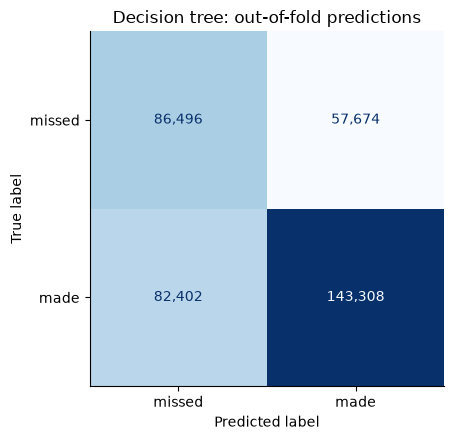

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, labels=[0, 1],
                                        display_labels=['missed', 'made'], cmap='Blues',
                                        colorbar=False, values_format=',d', ax=ax)
ax.grid(False)
ax.set_title(f'{best_name.capitalize()}: out-of-fold predictions')
fig.tight_layout()
fig.savefig(FIGURES / 'confusion_matrix.png', dpi=150)
plt.show()

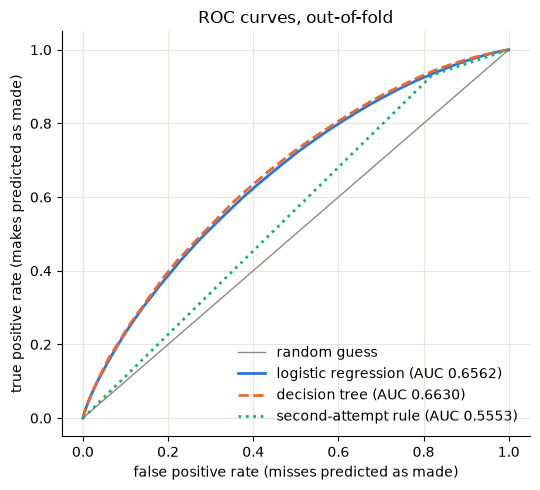

In [8]:
# Out-of-fold probabilities for all three, so every curve is on lifters the model
# never saw.
roc_probs = {}
for name, search in searches.items():
    roc_probs[name] = (oof_prob if name == best_name
                       else out_of_fold(search.best_estimator_, 'predict_proba')[:, 1])
roc_probs['second-attempt rule'] = out_of_fold(SecondAttemptRule(), 'predict_proba')[:, 1]

styles = {'logistic regression': (BLUE, '-'), 'decision tree': (ORANGE, '--'),
          'second-attempt rule': (AQUA, ':')}
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GREY, linewidth=1, label='random guess')
for name, prob in roc_probs.items():
    false_pos, true_pos, _ = roc_curve(y_train, prob)
    colour, line = styles[name]
    ax.plot(false_pos, true_pos, color=colour, linestyle=line, linewidth=2,
            label=f'{name} (AUC {roc_auc_score(y_train, prob):.4f})')
ax.set_xlabel('false positive rate (misses predicted as made)')
ax.set_ylabel('true positive rate (makes predicted as made)')
ax.set_title('ROC curves, out-of-fold')
ax.legend(loc='lower right', frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'roc_curves.png', dpi=150)
plt.show()

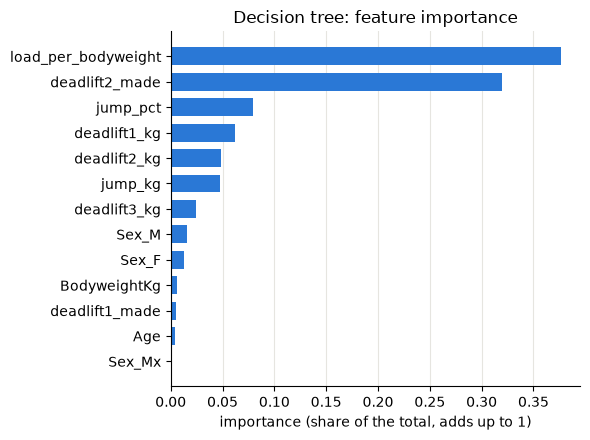

load_per_bodyweight    0.3761
deadlift2_made         0.3195
jump_pct               0.0793
deadlift1_kg           0.0616
deadlift2_kg           0.0483
jump_kg                0.0477
deadlift3_kg           0.0243
Sex_M                  0.0162
Sex_F                  0.0124
BodyweightKg           0.0060
deadlift1_made         0.0049
Age                    0.0038
Sex_Mx                 0.0000
dtype: float64

In [9]:
def input_names(search):
    """The input names after preprocessing, without the 'numeric__' and 'sex__' bits."""
    names = search.best_estimator_['prep'].get_feature_names_out()
    return [name.split('__', 1)[1] for name in names]


importance = pd.Series(tree_search.best_estimator_['model'].feature_importances_,
                       index=input_names(tree_search)).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.7)
ax.grid(axis='y', visible=False)
ax.set_xlabel('importance (share of the total, adds up to 1)')
ax.set_title('Decision tree: feature importance')
fig.tight_layout()
fig.savefig(FIGURES / 'tree_feature_importance.png', dpi=150)
plt.show()
importance.sort_values(ascending=False).round(4)

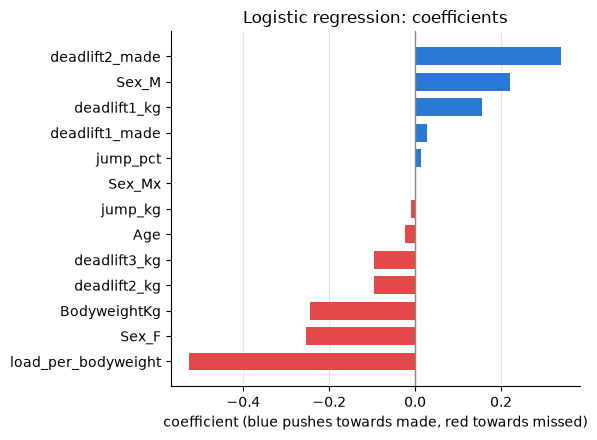

deadlift2_made         0.3404
Sex_M                  0.2217
deadlift1_kg           0.1567
deadlift1_made         0.0279
jump_pct               0.0148
Sex_Mx                 0.0001
jump_kg               -0.0098
Age                   -0.0240
deadlift3_kg          -0.0950
deadlift2_kg          -0.0963
BodyweightKg          -0.2454
Sex_F                 -0.2549
load_per_bodyweight   -0.5255
dtype: float64

In [10]:
# The inputs are scaled first, so each coefficient is the change for one standard
# deviation. Positive pushes towards "made", negative towards "missed".
coefs = pd.Series(lr_search.best_estimator_['model'].coef_[0],
                  index=input_names(lr_search)).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(coefs.index, coefs.values, color=[BLUE if c > 0 else RED for c in coefs], height=0.7)
ax.axvline(0, color=GREY, linewidth=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('coefficient (blue pushes towards made, red towards missed)')
ax.set_title('Logistic regression: coefficients')
fig.tight_layout()
fig.savefig(FIGURES / 'lr_coefficients.png', dpi=150)
plt.show()
coefs.sort_values(ascending=False).round(4)

## 7. Error analysis

In [11]:
# The groups I break the out-of-fold predictions down by.
age_band = pd.cut(train.Age, [-np.inf, 18, 24, 40, np.inf], right=False,
                  labels=['<18', '18-23', '24-39', '40+'])
load_quartile, load_edges = pd.qcut(train.load_per_bodyweight, 4, retbins=True,
                                    labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
print('load_per_bodyweight quartile edges:', np.round(load_edges, 2))

breakdowns = {
    'second attempt': train.deadlift2_made.map({1: 'made', 0: 'missed'}),
    'jump_pct': pd.cut(train.jump_pct, [-np.inf, 2.5, 5, 7.5, 10, np.inf],
                       labels=['<=2.5', '2.5-5', '5-7.5', '7.5-10', '>10']),
    'sex': train.Sex,
    'age': age_band.cat.add_categories('missing').fillna('missing'),
    'load_per_bodyweight': load_quartile,
}


def scores(actual, predicted):
    return {'rows': len(actual), 'success_rate': actual.mean(),
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'recall_missed': recall_score(actual, predicted, pos_label=0, zero_division=0)}


oof = pd.DataFrame({'made': y_train, 'predicted': oof_pred})
rows = [{'group': 'all rows', 'band': 'all', **scores(oof.made, oof.predicted)}]
for group, band in breakdowns.items():
    for value, part in oof.groupby(band, observed=True):
        rows.append({'group': group, 'band': value, **scores(part.made, part.predicted)})

# Only counts and rates here, nothing about any single lifter.
error_analysis = pd.DataFrame(rows).round(4)
error_analysis.to_csv(REPORTS / 'error_analysis.csv', index=False)
error_analysis

load_per_bodyweight quartile edges: [0.21 2.07 2.46 2.85 7.19]


,group,band,rows,success_rate,balanced_accuracy,recall_missed
0,all rows,all,369880,0.6102,0.6174,0.6000
1,second attempt,made,328593,0.6399,0.5973,0.5173
2,second attempt,missed,41287,0.3744,0.5190,0.9787
3,jump_pct,<=2.5,75173,0.4562,0.5412,0.9204
4,jump_pct,2.5-5,147452,0.6362,0.5766,0.4948
5,jump_pct,5-7.5,96048,0.6661,0.6022,0.4254
6,jump_pct,7.5-10,33833,0.6596,0.6295,0.4778
7,jump_pct,>10,17374,0.6511,0.6481,0.5247
8,sex,F,124807,0.6614,0.5952,0.4199
9,sex,M,245069,0.5842,0.6157,0.6747


## Where the model does badly

Overall the decision tree gets 0.6174 balanced accuracy on the out-of-fold predictions, but three groups are a lot worse. The worst is lifters who missed their second attempt (41,287 rows). The tree correctly calls 97.9% of the misses in this group, but 37.4% of these lifts are actually made, so its balanced accuracy there is only 0.5190, barely better than guessing. The heaviest quarter of lifts for bodyweight (load_per_bodyweight above 2.85) looks the same: 48.2% are made, the tree calls 93.8% of the misses correctly, and balanced accuracy is 0.5209. The third is the smallest jumps (2.5% or less), where 45.6% are made and balanced accuracy is 0.5412. In all three the model guesses "miss" for most lifts, so it gets most of the makes wrong. The lightest quarter goes the other way: the tree only spots 27.1% of the misses there. The Mx group has just 4 rows, which is too few to say anything about.

## Draft conclusion

My best model so far is the decision tree with a max depth of 8 and a minimum leaf size of 50. Its cross-validated balanced accuracy is 0.6174 (std 0.0016), against 0.5553 for the second-attempt rule, and logistic regression is close behind at 0.6113. The tree also spots far more of the misses: it catches 86,496 of the 144,170 missed lifts in the training set (recall 0.600), where the rule only gets 0.179. That comes at a cost, though. It wrongly calls 82,402 made lifts a miss, and its plain accuracy (0.6213) is lower than the rule's (0.6383). Most of what the tree uses comes from two inputs, load_per_bodyweight (0.3761) and whether the second attempt was made (0.3195).

There are some clear limits. My inputs don't say anything about a lifter's history at earlier meets or how their squat and bench went on the day. Some of the inputs overlap: jump_kg is just deadlift3_kg minus deadlift2_kg, and load_per_bodyweight is built from deadlift3_kg and bodyweight. That makes the logistic regression coefficients for those columns hard to read one at a time. All of these numbers come from cross-validation on the training set, and I haven't touched the test set yet. A balanced accuracy of about 0.62 is a real step up from the baselines, but it's still a long way from reliable.

For the final portfolio, I want to try an ensemble like a random forest or gradient boosting with the same tune() function and folds. After that I'll choose a threshold on the out-of-fold probabilities instead of using the default of 0.5, since moving it changes how many of the misses and makes the model gets right. Once I've settled on a final model, I'll score it on the test set once.